In [ ]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (2,807 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependen

In [ ]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [ ]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [ ]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Overwriting setup.sh


In [ ]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [1]:

%%writefile sinyal.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <complex>
#include <random>
#include <fstream>
using namespace std;

const double PI = acos(-1.0);

// Sinyalin DFT analizini hesaplar
vector<double> DFT(const vector<double>& sinyal) {
    int N = sinyal.size();
    vector<double> genlik(N / 2 + 1);

    for (int k = 0; k <= N / 2; k++) {
        complex<double> toplam(0, 0);

        for (int n = 0; n < N; n++) {
            double aci = -2 * PI * k * n / N;
            toplam += sinyal[n] *
                      complex<double>(cos(aci), sin(aci));
        }

        genlik[k] = abs(toplam) / N * 2;

        if (k == 0 || (N % 2 == 0 && k == N / 2))
            genlik[k] /= 2;
    }

    return genlik;
}

// Verileri CSV dosyasina kaydeder
void kaydet(string dosya, const vector<double>& x,
            const vector<double>& y) {
    ofstream cikti(dosya);
    cikti << "x,y\n";

    for (int i = 0; i < (int)x.size(); i++) {
        cikti << x[i] << "," << y[i] << "\n";
    }
    cikti.close();
}

int main() {
    const int N = 1000;
    const double Fs = 1000.0;

    vector<double> zaman(N);
    vector<double> sinyal1(N);
    vector<double> sinyal2(N);
    vector<double> toplamSinyal(N);

    mt19937 uretici(42);
    normal_distribution<double> gurultu(0.0, 1.0);

    // Sinyalleri olustur ve gurultu ekle
    for (int n = 0; n < N; n++) {
        zaman[n] = n / Fs;

        sinyal1[n] = 12 * sin(2 * PI * 50 * zaman[n])
                     + gurultu(uretici);

        sinyal2[n] = 5 * sin(2 * PI * 30 * zaman[n])
                     + gurultu(uretici);

        toplamSinyal[n] = sinyal1[n] + sinyal2[n];
    }

    // Her sinyalin DFT analizini yap
    vector<double> dft1 = DFT(sinyal1);
    vector<double> dft2 = DFT(sinyal2);
    vector<double> dftToplam = DFT(toplamSinyal);

    // Frekans eksenini olustur
    vector<double> frekans(N / 2 + 1);
    for (int k = 0; k <= N / 2; k++) {
        frekans[k] = k * Fs / N;
    }

    // Grafik verilerini kaydet
    kaydet("sinyal1.csv", zaman, sinyal1);
    kaydet("sinyal2.csv", zaman, sinyal2);
    kaydet("toplam.csv", zaman, toplamSinyal);

    kaydet("dft1.csv", frekans, dft1);
    kaydet("dft2.csv", frekans, dft2);
    kaydet("dftToplam.csv", frekans, dftToplam);

    cout << "DFT analizleri tamamlandi!" << endl;
    cout << "1. sinyal: 50 Hz, genlik 12" << endl;
    cout << "2. sinyal: 30 Hz, genlik 5" << endl;

    cout << "Toplam sinyalin harmonik vektoru:" << endl;
    for (int k = 0; k <= N / 2; k++) {
        cout << frekans[k] << " Hz: "
             << dftToplam[k] << endl;
    }

    return 0;
}


Writing sinyal.cpp


In [2]:

!g++ sinyal.cpp -o sinyal
!./sinyal > sonuc.txt
!head -n 4 sonuc.txt


DFT analizleri tamamlandi!
1. sinyal: 50 Hz, genlik 12
2. sinyal: 30 Hz, genlik 5
Toplam sinyalin harmonik vektoru:


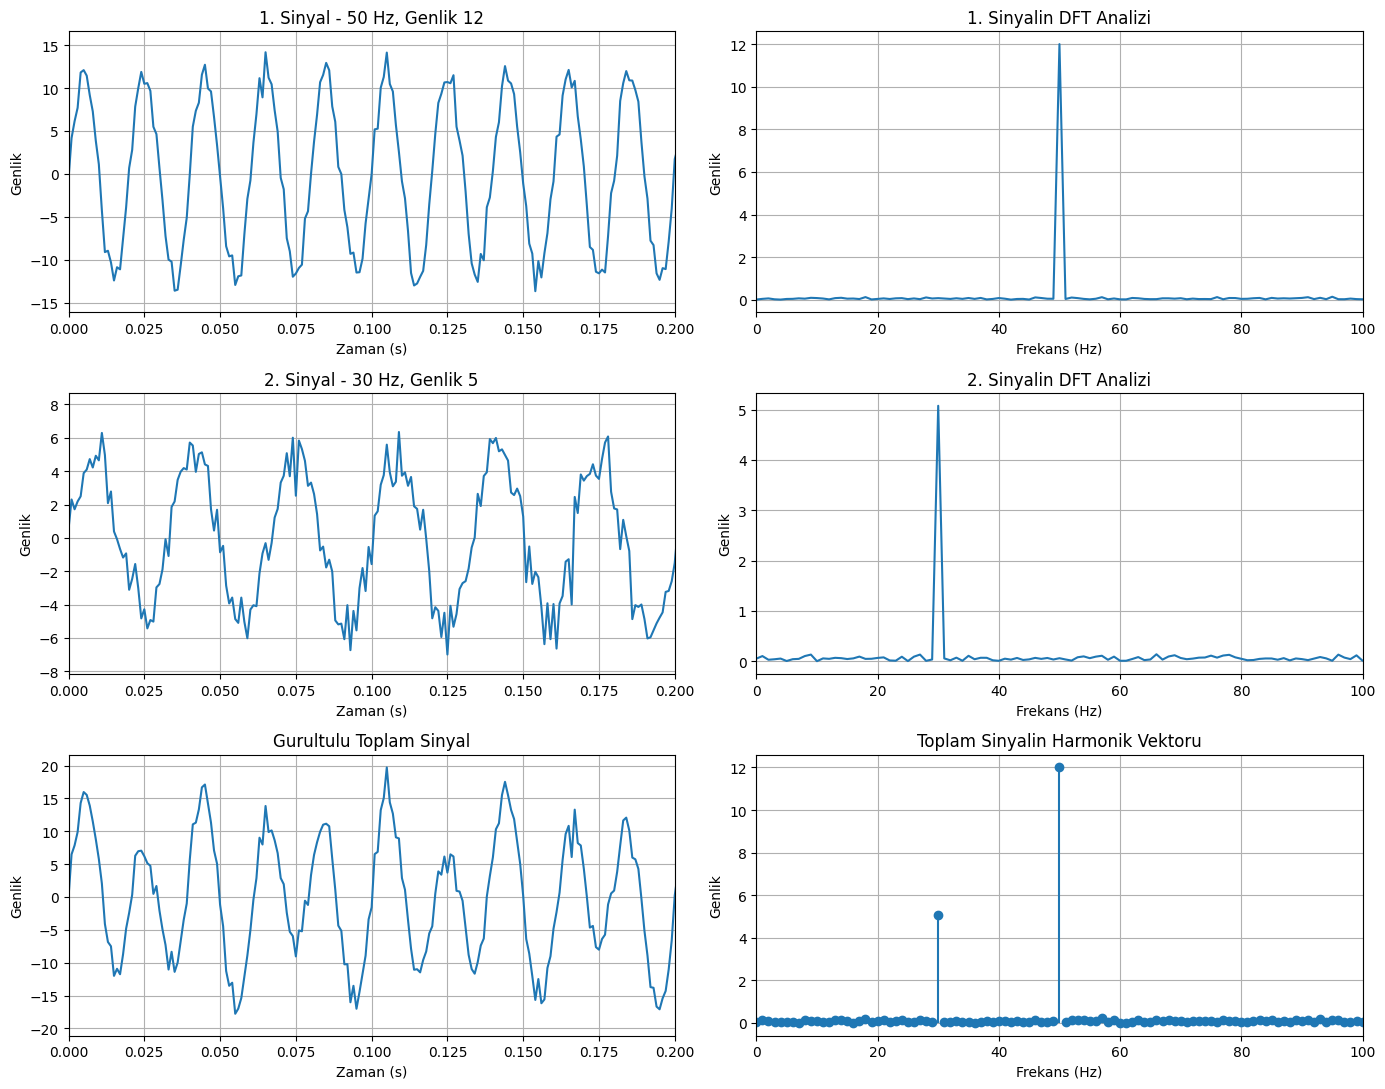

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# C++ kodunun olusturdugu dosyalari oku
s1 = pd.read_csv("sinyal1.csv")
s2 = pd.read_csv("sinyal2.csv")
st = pd.read_csv("toplam.csv")

d1 = pd.read_csv("dft1.csv")
d2 = pd.read_csv("dft2.csv")
dt = pd.read_csv("dftToplam.csv")

fig, ax = plt.subplots(3, 2, figsize=(14, 11))

# Birinci sinyal
ax[0, 0].plot(s1["x"], s1["y"])
ax[0, 0].set_title("1. Sinyal - 50 Hz, Genlik 12")
ax[0, 0].set_xlabel("Zaman (s)")
ax[0, 0].set_ylabel("Genlik")
ax[0, 0].set_xlim(0, 0.2)

# Birinci sinyalin DFT sonucu
ax[0, 1].plot(d1["x"], d1["y"])
ax[0, 1].set_title("1. Sinyalin DFT Analizi")
ax[0, 1].set_xlabel("Frekans (Hz)")
ax[0, 1].set_ylabel("Genlik")
ax[0, 1].set_xlim(0, 100)

# Ikinci sinyal
ax[1, 0].plot(s2["x"], s2["y"])
ax[1, 0].set_title("2. Sinyal - 30 Hz, Genlik 5")
ax[1, 0].set_xlabel("Zaman (s)")
ax[1, 0].set_ylabel("Genlik")
ax[1, 0].set_xlim(0, 0.2)

# Ikinci sinyalin DFT sonucu
ax[1, 1].plot(d2["x"], d2["y"])
ax[1, 1].set_title("2. Sinyalin DFT Analizi")
ax[1, 1].set_xlabel("Frekans (Hz)")
ax[1, 1].set_ylabel("Genlik")
ax[1, 1].set_xlim(0, 100)

# Toplam sinyal
ax[2, 0].plot(st["x"], st["y"])
ax[2, 0].set_title("Gurultulu Toplam Sinyal")
ax[2, 0].set_xlabel("Zaman (s)")
ax[2, 0].set_ylabel("Genlik")
ax[2, 0].set_xlim(0, 0.2)

# Toplam sinyalin harmonik vektoru
ax[2, 1].stem(dt["x"], dt["y"],
              basefmt=" ")
ax[2, 1].set_title("Toplam Sinyalin Harmonik Vektoru")
ax[2, 1].set_xlabel("Frekans (Hz)")
ax[2, 1].set_ylabel("Genlik")
ax[2, 1].set_xlim(0, 100)

for a in ax.flat:
    a.grid(True)

plt.tight_layout()
plt.savefig("DFT_sonuclari.png", dpi=200)
plt.show()
